# Berka Bank: Analysis and Validation in Python

Companion notebook to the six-page Power BI report on the Berka bank dataset. It does three jobs:

1. **Validates the data.** Keys, orphan rows, dates, balances and loan arithmetic are checked directly on the source CSV files, before any modelling.
2. **Recomputes the numbers in the report** (pages 1 to 5) independently of Power BI, and runs the statistical tests behind the conclusions.
3. **Goes one step further.** Sections marked *Extra* add checks that are not on the report.

**Dataset.** Berka dataset from the PKDD'99 Discovery Challenge: an anonymised Czech bank with 4,500 accounts, 1.06 million transactions, 682 loans and 892 cards, from January 1993 to December 1998. Amounts are in Czech crowns (CZK).

**How to run.** Put the eight CSV files (`account`, `card`, `client`, `disp`, `district`, `loan`, `order`, `trans`) in a `data/` folder next to this notebook, install `pandas`, `numpy`, `scipy` and `matplotlib`, and choose *Run All*.

| Section | Report page |
| --- | --- |
| 1. Data quality checks | 6. About the Data |
| 2. Headline numbers | 1. Executive Summary |
| 3. Customers and products | 2. Customers & Products |
| 4. Cash flow and behaviour | 3. Cash Flow & Behaviour |
| 5. Districts and regions | 4. Districts & Regions |
| 6. Loan risk | 5. Loan Risk |
| 7. Summary of findings and limitations | All pages |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from scipy import stats
from IPython.display import display

DATA_DIR = Path("data")          # folder with the eight Berka CSV files

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30
pd.options.display.max_colwidth = 110

# Colours used in the Power BI report, so charts look like part of the same project
NAVY, BLUE, LIGHT, CORAL, GREY = "#12355B", "#2F6DB5", "#7FA6D6", "#D1495B", "#8A97A8"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.edgecolor": GREY, "axes.labelcolor": "#4A5A6E",
    "xtick.color": "#4A5A6E", "ytick.color": "#4A5A6E",
})

c:\Users\patri\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
def read(name):
    """Read one Berka CSV file (semicolon-separated)."""
    return pd.read_csv(DATA_DIR / f"{name}.csv", sep=";", low_memory=False)


account, client, disp, district = read("account"), read("client"), read("disp"), read("district")
loan, order, card, trans = read("loan"), read("order"), read("card"), read("trans")

tables = {"account": account, "client": client, "disp": disp, "district": district,
          "loan": loan, "order": order, "card": card, "trans": trans}
pd.DataFrame({"rows": {name: len(df) for name, df in tables.items()},
              "columns": {name: df.shape[1] for name, df in tables.items()}})

,rows,columns
account,4500,4
client,5369,3
disp,5369,4
district,77,16
loan,682,7
order,6471,6
card,892,4
trans,1056320,10


### Preparation

The source files store dates as `YYMMDD` integers and use Czech codes. This cell converts the dates and creates the three fields that the rest of the notebook relies on: the income/expense flag, the signed amount and the loan outcome flag. These are the same definitions used in the Power BI model.

In [3]:
def to_date(yymmdd):
    """Convert the YYMMDD integers used in the files into dates (all dates fall in 1993-1998)."""
    return pd.to_datetime(yymmdd.astype(str).str.zfill(6), format="%y%m%d")


account["open_date"] = to_date(account["date"])
loan["loan_date"] = to_date(loan["date"])
loan["year"] = loan["loan_date"].dt.year
card["issue_date"] = to_date(card["issued"].str[:6])        # "930107 00:00:00" -> 930107
trans["trans_date"] = to_date(trans["date"])
trans["year"] = trans["trans_date"].dt.year
trans["month"] = trans["trans_date"].dt.month

# Money in / money out.  PRIJEM = credit.  VYDAJ (debit) and VYBER (cash withdrawal) = money out.
trans["is_income"] = trans["type"].eq("PRIJEM")
trans["signed_amount"] = np.where(trans["is_income"], trans["amount"], -trans["amount"])

# Loan outcome.  A = finished, paid | B = finished, NOT paid | C = running, on time | D = running, in debt
loan["is_problem"] = loan["status"].isin(["B", "D"])

# Cards are attached to a disposition (a person's right over an account); link each card to its account
card_account = card.merge(disp[["disp_id", "account_id"]], on="disp_id")

## 1. Data quality checks

*Report page 6, "About the Data".* Before measuring anything, the notebook tests whether the data can be trusted. Each check is recorded in one results table at the end of the section. A check that fails would show as `FAIL`, so nothing is hidden.

In [4]:
results = []


def check(name, passed, detail):
    """Record the outcome of one validation check."""
    results.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})


# 1) Primary keys must be unique
keys = {"account": "account_id", "client": "client_id", "disp": "disp_id", "district": "A1",
        "loan": "loan_id", "order": "order_id", "card": "card_id", "trans": "trans_id"}
duplicates = {name: int(tables[name][key].duplicated().sum()) for name, key in keys.items()}
check("Primary keys are unique (8 tables)", sum(duplicates.values()) == 0,
      f"{sum(duplicates.values())} duplicate keys")

# 2) Foreign keys: every child row must point to a parent row that exists
foreign_keys = [
    ("disp.client_id",      disp["client_id"],      client["client_id"]),
    ("disp.account_id",     disp["account_id"],     account["account_id"]),
    ("card.disp_id",        card["disp_id"],        disp["disp_id"]),
    ("loan.account_id",     loan["account_id"],     account["account_id"]),
    ("order.account_id",    order["account_id"],    account["account_id"]),
    ("trans.account_id",    trans["account_id"],    account["account_id"]),
    ("account.district_id", account["district_id"], district["A1"]),
    ("client.district_id",  client["district_id"],  district["A1"]),
]
orphans = {name: int((~child.isin(parent)).sum()) for name, child, parent in foreign_keys}
check("No orphan rows (8 relationships)", sum(orphans.values()) == 0,
      f"{sum(orphans.values())} orphan rows")

# 3) Every account has exactly one owner
owner_rows = disp[disp["type"] == "OWNER"]
check("Exactly one owner per account",
      owner_rows["account_id"].is_unique and len(owner_rows) == len(account),
      f"{len(owner_rows):,} owners for {len(account):,} accounts")

# 4) Nothing may be dated before its account was opened
open_date = account.set_index("account_id")["open_date"]
too_early = {
    "loans": int((loan["loan_date"] < loan["account_id"].map(open_date)).sum()),
    "cards": int((card_account["issue_date"] < card_account["account_id"].map(open_date)).sum()),
    "transactions": int((trans["trans_date"] < trans["account_id"].map(open_date)).sum()),
}
check("Nothing is dated before its account was opened", sum(too_early.values()) == 0,
      ", ".join(f"{n} {k}" for k, n in too_early.items()))

# 5) Loan arithmetic: monthly payment x duration (months) should equal the loan amount
loan_gap = (loan["payments"] * loan["duration"] - loan["amount"]).abs()
check("Loan payment x duration = amount", bool((loan_gap <= 1).all()),
      f"{int((loan_gap <= 1).sum())} of {len(loan)} loans match (tolerance 1 CZK)")

**Balance reconciliation.** The `balance` column should equal the running total of all movements on the account. Transactions made on the same day have no reliable order in the file, so the test works on **account-days**: the end-of-day running total must match one of the balances recorded on that day.

The source rounds amounts inconsistently, so an exact match to the cent is not expected. The check uses a stated tolerance of 3 CZK instead of pretending the match is perfect.

In [5]:
t = trans.sort_values(["account_id", "date", "trans_id"])
running_total = t.groupby("account_id")["signed_amount"].cumsum()
day_key = [t["account_id"], t["date"]]
end_of_day_total = running_total.groupby(day_key).transform("last")

# For each account-day: distance between the end-of-day total and the closest recorded balance
closest_gap = (t["balance"] - end_of_day_total).abs().groupby(day_key).min()

check("Balance = running total of movements (per account-day)", bool(closest_gap.max() <= 3),
      f"{len(closest_gap):,} account-days, largest gap {closest_gap.max():.1f} CZK, "
      f"exact to the cent on {(closest_gap < 0.005).mean():.1%}")

pd.DataFrame(results).set_index("check")

,result,detail
check,,
Primary keys are unique (8 tables),PASS,0 duplicate keys
No orphan rows (8 relationships),PASS,0 orphan rows
Exactly one owner per account,PASS,"4,500 owners for 4,500 accounts"
Nothing is dated before its account was opened,PASS,"0 loans, 0 cards, 0 transactions"
Loan payment x duration = amount,PASS,682 of 682 loans match (tolerance 1 CZK)
Balance = running total of movements (per account-day),PASS,"814,768 account-days, largest gap 2.8 CZK, exact to the cent on 26.7%"


## 2. Headline numbers

*Report page 1, "Executive Summary".* Size of the data and the overall financial result. Income is every credit (`PRIJEM`); expenses are every debit and cash withdrawal (`VYDAJ`, `VYBER`).

In [6]:
n_trans = len(trans)
income = trans.loc[trans["is_income"], "amount"].sum()
expenses = trans.loc[~trans["is_income"], "amount"].sum()
net_flow = income - expenses

pd.Series({
    "Transactions": f"{n_trans:,}",
    "Accounts": f"{account['account_id'].nunique():,}",
    "First / last transaction": f"{trans['trans_date'].min():%d %b %Y} / {trans['trans_date'].max():%d %b %Y}",
    "Income (CZK)": f"{income / 1e6:,.1f} M",
    "Expenses (CZK)": f"{expenses / 1e6:,.1f} M",
    "Net flow (CZK)": f"{net_flow / 1e6:,.1f} M",
    "Expense ratio, all years": f"{expenses / income:.2%}",
}, name="Value").to_frame()

,Value
Transactions,"1,056,320"
Accounts,"4,500"
First / last transaction,01 Jan 1993 / 31 Dec 1998
Income (CZK),"3,227.5 M"
Expenses (CZK),"3,030.3 M"
Net flow (CZK),197.2 M
"Expense ratio, all years",93.89%


In [7]:
flows = trans.assign(income=np.where(trans["is_income"], trans["amount"], 0.0),
                     expenses=np.where(trans["is_income"], 0.0, trans["amount"]))
yearly = flows.groupby("year").agg(transactions=("trans_id", "size"),
                                  income=("income", "sum"), expenses=("expenses", "sum"))
yearly["net_flow"] = yearly["income"] - yearly["expenses"]
yearly["expense_ratio"] = yearly["expenses"] / yearly["income"]

shown = yearly.copy()
shown[["income", "expenses", "net_flow"]] /= 1e6          # millions of CZK
shown["expense_ratio"] *= 100                              # per cent
shown.columns = ["transactions", "income (M)", "expenses (M)", "net flow (M)", "expense ratio (%)"]
shown

,transactions,income (M),expenses (M),net flow (M),expense ratio (%)
year,,,,,
1993,28205,120.44,83.87,36.58,69.63
1994,91628,278.54,260.26,18.28,93.44
1995,133022,396.07,371.66,24.40,93.84
1996,196779,606.77,557.08,49.69,91.81
1997,284409,864.69,823.64,41.06,95.25
1998,322277,960.96,933.82,27.15,97.18


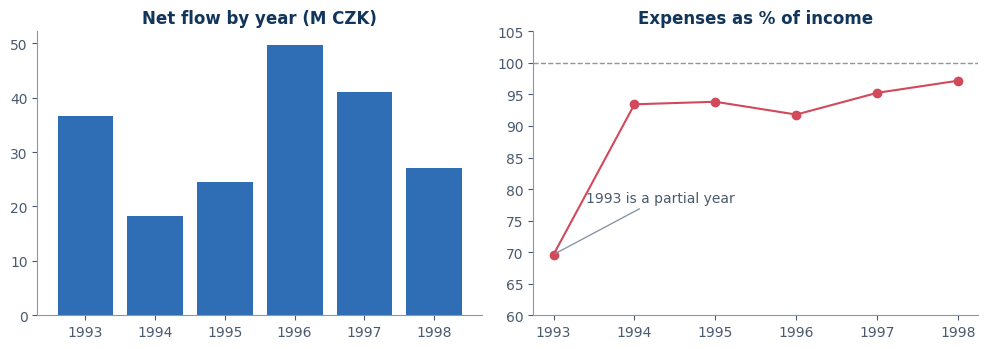

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

ax1.bar(yearly.index, yearly["net_flow"] / 1e6, color=BLUE)
ax1.set_title("Net flow by year (M CZK)")

ax2.plot(yearly.index, yearly["expense_ratio"] * 100, color=CORAL, marker="o")
ax2.axhline(100, color=GREY, ls="--", lw=1)
ax2.set_ylim(60, 105)
ax2.set_title("Expenses as % of income")
ax2.annotate("1993 is a partial year", (1993, yearly.loc[1993, "expense_ratio"] * 100),
             xytext=(1993.4, 78), color="#4A5A6E", arrowprops=dict(arrowstyle="-", color=GREY))
plt.tight_layout()
plt.show()

**Average balance has more than one possible definition**, and they give different answers. The report uses the first one (every balance recorded after a transaction), which gives more weight to accounts with more activity. Writing the definition down avoids an argument later.

In [9]:
per_account = t.groupby("account_id")["balance"]          # t is sorted by account, date, trans_id

pd.Series({
    "Mean balance after each transaction (report definition)": trans["balance"].mean(),
    "Mean of each account's latest balance": per_account.last().mean(),
    "Mean of each account's own average balance": per_account.mean().mean(),
}, name="CZK").to_frame()

,CZK
Mean balance after each transaction (report definition),"38,518.33"
Mean of each account's latest balance,"43,808.94"
Mean of each account's own average balance,"36,667.86"


## 3. Customers and products

*Report page 2, "Customers & Products".* Who the 4,500 account owners are and which products they hold. Owner age is **1998 minus birth year**; the birth year is the first two digits of the Czech birth number.

In [10]:
client["birth_year"] = 1900 + client["birth_number"] // 10000
client["age"] = 1998 - client["birth_year"]               # age at the end of the data

owners = (disp.loc[disp["type"] == "OWNER", ["account_id", "client_id"]]
              .merge(client[["client_id", "age"]], on="client_id"))
owners["age_band"] = pd.cut(owners["age"], bins=[0, 24, 34, 44, 54, 64, 120],
                            labels=["Under 25", "25-34", "35-44", "45-54", "55-64", "65+"])

print(f"Owners: {len(owners):,} | mean age {owners['age'].mean():.1f} | median age {owners['age'].median():.0f}")
owners["age_band"].value_counts().sort_index().to_frame("owners")

Owners: 4,500 | mean age 44.1 | median age 43


,owners
age_band,
Under 25,715
25-34,819
35-44,798
45-54,832
55-64,697
65+,639


In [11]:
# Product holdings per account.  A "standing order" is a recurring payment set up on the account.
has_card = account["account_id"].isin(card_account["account_id"])
has_loan = account["account_id"].isin(loan["account_id"])
has_order = account["account_id"].isin(order["account_id"])

products = pd.DataFrame({"accounts": [has_card.sum(), has_loan.sum(), has_order.sum()]},
                        index=["Card", "Loan", "Standing order"])
products["share of accounts (%)"] = products["accounts"] / len(account) * 100
products

,accounts,share of accounts (%)
Card,892,19.82
Loan,682,15.16
Standing order,3758,83.51


In [12]:
# Card types and the age of the owner who holds them
card_owner = card_account.merge(owners[["account_id", "age"]], on="account_id")
card_owner.groupby("type")["age"].agg(cards="size", youngest="min", median="median", oldest="max")

,cards,youngest,median,oldest
type,,,,
classic,659,21,43.00,80
gold,88,21,44.50,68
junior,145,16,19.00,24


**Customers with no product.** "Product" here means a card, a loan, or a standing order that is not a loan repayment (`k_symbol = UVER`). Loan repayments are left out because they exist only as a consequence of the loan.

In [13]:
loan_repayment_orders = order["k_symbol"] == "UVER"
owners["has_card"] = owners["account_id"].isin(card_account["account_id"])
owners["has_loan"] = owners["account_id"].isin(loan["account_id"])
owners["has_order"] = owners["account_id"].isin(order.loc[~loan_repayment_orders, "account_id"])
owners["no_product"] = ~(owners["has_card"] | owners["has_loan"] | owners["has_order"])

under_25 = owners[owners["age"] < 25]
print(f"Owners under 25: {len(under_25):,} | with no product: {under_25['no_product'].sum()} "
      f"({under_25['no_product'].mean():.1%})")

by_band = owners.groupby("age_band", observed=True)[["has_card", "has_loan", "no_product"]].mean() * 100
by_band.columns = ["with a card (%)", "with a loan (%)", "with no product (%)"]
by_band

Owners under 25: 715 | with no product: 185 (25.9%)


,with a card (%),with a loan (%),with no product (%)
age_band,,,
Under 25,28.11,13.15,25.87
25-34,20.76,20.39,11.97
35-44,20.05,18.80,14.04
45-54,23.32,19.23,12.14
55-64,21.81,15.93,10.04
65+,2.35,0.00,0.63


**Extra: the product mix follows age closely.** Junior cards go only to owners under 25 (aged 16 to 24), and no owner aged 64 or over has a loan. Owners under 25 are also much more likely to hold no product at all (about 26%, against 10-14% in the other working-age bands). These patterns come from how the bank sells its products, so they are worth knowing before drawing conclusions about any age group.

Owners with a loan: ages 18 to 63; owners aged 64+ with a loan: 0


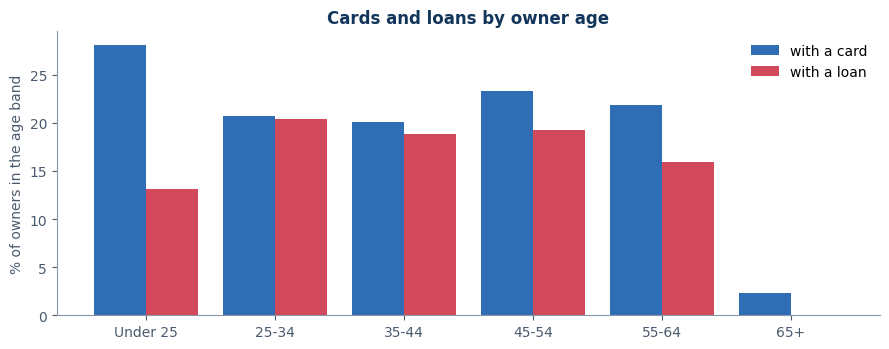

In [14]:
loan_owner_age = owners.loc[owners["has_loan"], "age"]
print(f"Owners with a loan: ages {loan_owner_age.min()} to {loan_owner_age.max()}; "
      f"owners aged 64+ with a loan: {int((owners['age'] >= 64).mul(owners['has_loan']).sum())}")

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(by_band))
ax.bar(x - 0.2, by_band["with a card (%)"], width=0.4, color=BLUE, label="with a card")
ax.bar(x + 0.2, by_band["with a loan (%)"], width=0.4, color=CORAL, label="with a loan")
ax.set_xticks(x, by_band.index)
ax.set_ylabel("% of owners in the age band")
ax.set_title("Cards and loans by owner age")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4. Cash flow and behaviour

*Report page 3, "Cash Flow & Behaviour".* Does income cover spending, and when does it not? The ratio is calculated from 1994 onward because 1993 is a partial year: accounts were still being opened, so it has far fewer transactions and a misleading ratio.

In [15]:
ratio_all = expenses / income
full = flows[flows["year"] >= 1994]
ratio_94_98 = full["expenses"].sum() / full["income"].sum()

print(f"Expense ratio, all years : {ratio_all:.2%}")
print(f"Expense ratio, 1994-1998 : {ratio_94_98:.2%}")
print(f"Transactions 1993 vs 1994: {yearly.loc[1993, 'transactions']:,} vs {yearly.loc[1994, 'transactions']:,}")

Expense ratio, all years : 93.89%
Expense ratio, 1994-1998 : 94.83%
Transactions 1993 vs 1994: 28,205 vs 91,628


**Which months spend more than they earn?** Every month from 1994 to 1998 is compared on its own expense ratio. A ratio above 100% means a deficit month.

In [16]:
monthly = full.groupby(["year", "month"])[["income", "expenses"]].sum()
monthly["ratio"] = monthly["expenses"] / monthly["income"]

deficit = monthly[monthly["ratio"] > 1].copy()
deficit["expenses as % of income"] = (deficit["ratio"] * 100).round(1)
print(f"Months analysed: {len(monthly)} | deficit months: {len(deficit)}")
deficit[["expenses as % of income"]].reset_index().pivot(index="year", columns="month",
                                                          values="expenses as % of income")

Months analysed: 60 | deficit months: 10


month,1,6
year,,
1994,128.80,102.20
1995,146.40,105.00
1996,142.00,105.10
1997,139.90,107.20
1998,142.30,113.50


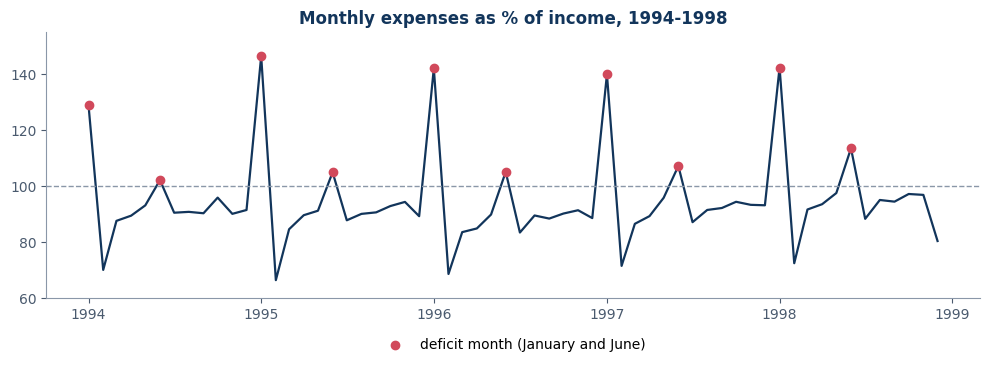

In [17]:
dates = pd.to_datetime(monthly.reset_index().assign(day=1)[["year", "month", "day"]])
ratio = monthly["ratio"].to_numpy() * 100

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(dates, ratio, color=NAVY, lw=1.6)
ax.axhline(100, color=GREY, ls="--", lw=1)
over = ratio > 100
ax.scatter(dates[over], ratio[over], color=CORAL, zorder=3, label="deficit month (January and June)")
ax.set_ylim(60, 155)
ax.set_title("Monthly expenses as % of income, 1994-1998")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

**Accounts in the red.** An account counts as "in the red" if its balance fell below zero **at least once**, so the test uses each account's minimum balance. That is different from ending overdrawn, which is much rarer.

In [18]:
min_balance = trans.groupby("account_id")["balance"].min()
min_balance_94 = trans[trans["year"] >= 1994].groupby("account_id")["balance"].min()
ending_balance = per_account.last()

pd.Series({
    "Accounts that went below zero at least once (all years)": int((min_balance < 0).sum()),
    "Accounts that went below zero at least once (1994-1998)": int((min_balance_94 < 0).sum()),
    "Accounts that ended the period below zero": int((ending_balance < 0).sum()),
    "Share of accounts that dipped below zero (all years)": f"{(min_balance < 0).mean():.1%}",
}, name="Value").to_frame()

,Value
Accounts that went below zero at least once (all years),288
Accounts that went below zero at least once (1994-1998),286
Accounts that ended the period below zero,39
Share of accounts that dipped below zero (all years),6.4%


**Behaviour: what is the money spent on?** Cash withdrawals dominate. January also stands out: cash withdrawals run at about three times the level of February. The data does not say why.

In [19]:
spend = trans.loc[~trans["is_income"]]
by_operation = spend.groupby("operation")["amount"].sum().sort_values(ascending=False)
cash_share = by_operation[["VYBER", "VYBER KARTOU"]].sum() / by_operation.sum()
print(f"Cash and card withdrawals as a share of all spending: {cash_share:.1%}")

cash_by_month = trans[trans["operation"] == "VYBER"].groupby("month").size()
print(f"Cash withdrawals in January vs February (whole period): "
      f"{cash_by_month[1]:,} vs {cash_by_month[2]:,}  ({cash_by_month[1] / cash_by_month[2]:.1f}x)")

(by_operation / 1e6).round(1).to_frame("spent (M CZK)")

Cash and card withdrawals as a share of all spending: 77.8%
Cash withdrawals in January vs February (whole period): 74,484 vs 24,258  (3.1x)


,spent (M CZK)
operation,
VYBER,"2,339.50"
PREVOD NA UCET,672.60
VYBER KARTOU,18.20


## 5. Districts and regions

*Report page 4, "Districts & Regions".* Does where people live explain how they bank? Two questions, two tests:

- **Salary vs balance.** Is the average salary of a district related to the average balance of its accounts? Tested with a Pearson correlation, repeated without Prague because one large, high-salary point can drive a correlation on its own. A Spearman rank correlation is added as a check that does not depend on the shape of the relationship.
- **Regions.** Do regions differ in card ownership or in loan problems? Tested with a chi-square test, which asks whether the differences are larger than chance would produce.

In [20]:
# District-level table.  A11 = average salary, A2 = district name, A3 = region.
# Average balance uses the report definition: mean balance over all transactions of the district's accounts.
tx = trans[["account_id", "balance"]].merge(account[["account_id", "district_id"]], on="account_id")
by_district = (tx.groupby("district_id")["balance"].mean().to_frame("avg_balance")
                 .join(district.set_index("A1")[["A2", "A3", "A11"]]
                       .rename(columns={"A2": "district", "A3": "region", "A11": "avg_salary"}))
                 .join(account.groupby("district_id").size().rename("accounts")))

print(f"Districts: {len(by_district)} | accounts per district: median {by_district['accounts'].median():.0f}, "
      f"range {by_district['accounts'].min()} to {by_district['accounts'].max()}")
by_district.sort_values("avg_salary", ascending=False).head(5)

Districts: 77 | accounts per district: median 48, range 32 to 554


,avg_balance,district,region,avg_salary,accounts
district_id,,,,,
1,"38,883.76",Hl.m. Praha,Prague,12541,554
8,"36,258.21",Mlada Boleslav,central Bohemia,11277,56
26,"37,504.77",Plzen - mesto,west Bohemia,10787,45
74,"39,508.26",Ostrava - mesto,north Moravia,10673,135
39,"34,063.72",Most,north Bohemia,10446,41


In [21]:
rows = []
for label, sample in [("All districts", by_district), ("Without Prague", by_district.drop(index=1))]:
    r, p = stats.pearsonr(sample["avg_salary"], sample["avg_balance"])
    rho, p_rho = stats.spearmanr(sample["avg_salary"], sample["avg_balance"])
    rows.append({"sample": label, "districts": len(sample), "Pearson r": f"{r:.2f}", "p-value": f"{p:.2f}",
                 "Spearman rho": f"{rho:.2f}", "p-value (Spearman)": f"{p_rho:.2f}"})
pd.DataFrame(rows).set_index("sample")

,districts,Pearson r,p-value,Spearman rho,p-value (Spearman)
sample,,,,,
All districts,77,-0.09,0.43,-0.04,0.70
Without Prague,76,-0.12,0.29,-0.05,0.64


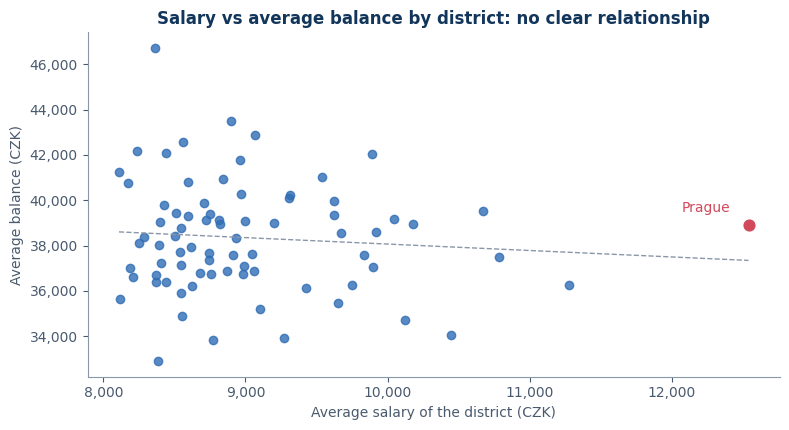

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.4))
others = by_district.drop(index=1)
ax.scatter(others["avg_salary"], others["avg_balance"], color=BLUE, alpha=0.8, s=36)
ax.scatter(*by_district.loc[1, ["avg_salary", "avg_balance"]], color=CORAL, s=60, zorder=3)
ax.annotate("Prague", by_district.loc[1, ["avg_salary", "avg_balance"]].to_numpy(float),
            xytext=(-48, 10), textcoords="offset points", color=CORAL)

slope, intercept = np.polyfit(by_district["avg_salary"], by_district["avg_balance"], 1)
xs = np.array([by_district["avg_salary"].min(), by_district["avg_salary"].max()])
ax.plot(xs, slope * xs + intercept, color=GREY, ls="--", lw=1)

ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Average salary of the district (CZK)")
ax.set_ylabel("Average balance (CZK)")
ax.set_title("Salary vs average balance by district: no clear relationship")
plt.tight_layout()
plt.show()

In [23]:
# Card ownership by region (region of the district where the account is held)
acc_region = (account.merge(district[["A1", "A3"]], left_on="district_id", right_on="A1")
                     .rename(columns={"A3": "region"}))
acc_region["has_card"] = acc_region["account_id"].isin(card_account["account_id"])

region_cards = acc_region.groupby("region")["has_card"].agg(accounts="size", with_card="sum", share="mean")
region_cards["share (%)"] = region_cards.pop("share") * 100

chi2, p_cards, dof, _ = stats.chi2_contingency(pd.crosstab(acc_region["region"], acc_region["has_card"]))
print(f"Card ownership by region: chi-square = {chi2:.1f}, degrees of freedom = {dof}, p = {p_cards:.3f}")
region_cards.sort_values("share (%)")

Card ownership by region: chi-square = 22.9, degrees of freedom = 7, p = 0.002


,accounts,with_card,share (%)
region,,,
south Moravia,778,128,16.45
north Moravia,793,136,17.15
east Bohemia,544,99,18.20
south Bohemia,370,74,20.00
central Bohemia,574,117,20.38
west Bohemia,430,95,22.09
Prague,554,132,23.83
north Bohemia,457,111,24.29


In [24]:
# Problem loans by region
loan_region = loan.merge(acc_region[["account_id", "region"]], on="account_id")
region_loans = loan_region.groupby("region")["is_problem"].agg(loans="size", problem="sum", rate="mean")
region_loans["problem rate (%)"] = region_loans.pop("rate") * 100

chi2_l, p_loans, dof_l, _ = stats.chi2_contingency(pd.crosstab(loan_region["region"], loan_region["is_problem"]))
print(f"Problem loans by region: chi-square = {chi2_l:.1f}, degrees of freedom = {dof_l}, p = {p_loans:.2f}")
print(f"Loans per region: {region_loans['loans'].min()} to {region_loans['loans'].max()}")
region_loans.sort_values("problem rate (%)")

Problem loans by region: chi-square = 10.7, degrees of freedom = 7, p = 0.15
Loans per region: 57 to 129


,loans,problem,problem rate (%)
region,,,
north Bohemia,61,1,1.64
Prague,84,7,8.33
south Moravia,129,13,10.08
east Bohemia,84,9,10.71
central Bohemia,90,10,11.11
south Bohemia,60,9,15.00
north Moravia,117,18,15.38
west Bohemia,57,9,15.79


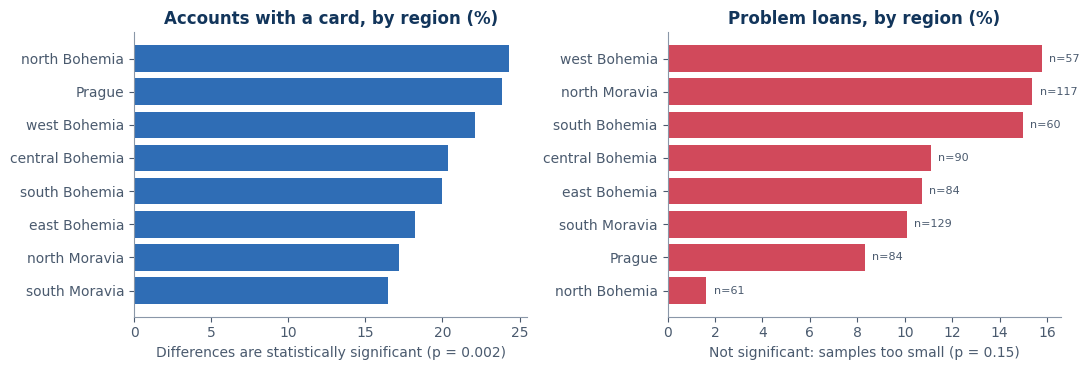

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

order_c = region_cards.sort_values("share (%)")
ax1.barh(order_c.index, order_c["share (%)"], color=BLUE)
ax1.set_title("Accounts with a card, by region (%)")
ax1.set_xlabel(f"Differences are statistically significant (p = {p_cards:.3f})")

order_l = region_loans.sort_values("problem rate (%)")
ax2.barh(order_l.index, order_l["problem rate (%)"], color=CORAL)
for i, (rate, n) in enumerate(zip(order_l["problem rate (%)"], order_l["loans"])):
    ax2.text(rate + 0.3, i, f"n={n}", va="center", fontsize=8, color="#4A5A6E")
ax2.set_title("Problem loans, by region (%)")
ax2.set_xlabel(f"Not significant: samples too small (p = {p_loans:.2f})")
plt.tight_layout()
plt.show()

## 6. Loan risk

*Report page 5, "Loan Risk".* A **problem loan** is one with status `B` (finished, not repaid) or `D` (still running, client in debt). The problem rate is problem loans divided by all loans.

In [26]:
status_meaning = {"A": "finished, repaid", "B": "finished, NOT repaid", "C": "running, on time", "D": "running, in debt"}
status = loan.groupby("status").agg(loans=("loan_id", "size"), amount=("amount", "sum"))
status["amount (M CZK)"] = status.pop("amount") / 1e6
status.insert(0, "meaning", status.index.map(status_meaning))

problem_rate = loan["is_problem"].mean()
problem_money = loan.loc[loan["is_problem"], "amount"].sum() / loan["amount"].sum()
print(f"Loans: {len(loan)} | lent: {loan['amount'].sum() / 1e6:,.1f} M CZK")
print(f"Problem loans: {loan['is_problem'].sum()} ({problem_rate:.1%} of loans, {problem_money:.1%} of the money lent)")
status

Loans: 682 | lent: 103.3 M CZK
Problem loans: 76 (11.1% of loans, 15.1% of the money lent)


,meaning,loans,amount (M CZK)
status,,,
A,"finished, repaid",203,18.60
B,"finished, NOT repaid",31,4.36
C,"running, on time",403,69.08
D,"running, in debt",45,11.22


**By year of origination.** The rate looks stable at 13-14% from 1994 to 1997 and then collapses in 1998. That is **not** because 1998 loans are safer: they are too recent to have gone wrong yet. Statisticians call this *right-censoring*, and it is the main reason a headline problem rate can mislead.

In [27]:
by_year = loan.groupby("year")["is_problem"].agg(loans="size", problem="sum", rate="mean")
by_year["problem rate (%)"] = by_year.pop("rate") * 100
by_year

,loans,problem,problem rate (%)
year,,,
1993,20,4,20.00
1994,101,14,13.86
1995,90,12,13.33
1996,117,16,13.68
1997,196,26,13.27
1998,158,4,2.53


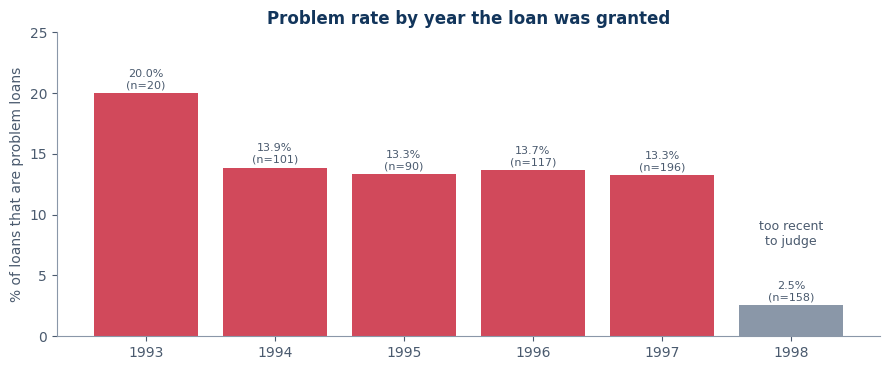

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colours = [CORAL if y != 1998 else GREY for y in by_year.index]
ax.bar(by_year.index, by_year["problem rate (%)"], color=colours)
for year, rate, n in zip(by_year.index, by_year["problem rate (%)"], by_year["loans"]):
    ax.text(year, rate + 0.4, f"{rate:.1f}%\n(n={n})", ha="center", fontsize=8, color="#4A5A6E")
ax.set_ylim(0, 25)
ax.set_ylabel("% of loans that are problem loans")
ax.set_title("Problem rate by year the loan was granted")
ax.text(1998, 7.5, "too recent\nto judge", ha="center", color="#4A5A6E", fontsize=9)
plt.tight_layout()
plt.show()

**Joint holders.** Some accounts have a second person with rights over the account (a *disponent*). The loans on those accounts behave very differently. Because the counts are small, the test used is **Fisher's exact test**, which stays valid with small numbers.

In [29]:
joint_accounts = disp.loc[disp["type"] == "DISPONENT", "account_id"].unique()
loan["has_joint_holder"] = loan["account_id"].isin(joint_accounts)

joint = loan.groupby("has_joint_holder")["is_problem"].agg(loans="size", problem="sum", rate="mean")
joint["problem rate (%)"] = joint.pop("rate") * 100
joint.index = ["no joint holder", "joint holder"]

_, p_fisher = stats.fisher_exact(pd.crosstab(loan["has_joint_holder"], loan["is_problem"]))
print(f"Fisher's exact test: p = {p_fisher:.1e}")
joint

Fisher's exact test: p = 6.5e-09


,loans,problem,problem rate (%)
no joint holder,537,76,14.15
joint holder,145,0,0.00


**Extra: is the joint-holder effect just a loan-size effect?** A fair challenge is that joint-holder accounts might simply have smaller or shorter loans. The table below compares them: the typical loan is somewhat smaller (about 105,000 against 122,000 CZK) and has the same duration (36 months). That small difference cannot explain a gap from 14% to 0%, so loan size alone is not the reason, but the group is small and the result should be read as a strong signal, not a rule.

In [30]:
loan.groupby("has_joint_holder").agg(loans=("loan_id", "size"),
                                     median_amount=("amount", "median"),
                                     median_duration_months=("duration", "median"))

,loans,median_amount,median_duration_months
has_joint_holder,,,
False,537,"122,472.00",36.00
True,145,"104,712.00",36.00


**Extra: larger loans carry more risk.** Splitting loans into four equally sized groups by amount shows that the problem rate rises sharply for the largest quarter. This is not on the report, but it is the kind of finding a credit team would act on.

In [31]:
loan["amount_quartile"] = pd.qcut(loan["amount"], 4,
                                  labels=["Q1 (smallest)", "Q2", "Q3", "Q4 (largest)"])
by_amount = loan.groupby("amount_quartile", observed=True).agg(
    loans=("loan_id", "size"), min_amount=("amount", "min"), max_amount=("amount", "max"),
    problem=("is_problem", "sum"), rate=("is_problem", "mean"))
by_amount["problem rate (%)"] = by_amount.pop("rate") * 100

chi2_a, p_amount, _, _ = stats.chi2_contingency(pd.crosstab(loan["amount_quartile"], loan["is_problem"]))
print(f"Chi-square test across the four groups: p = {p_amount:.4f}")
by_amount

Chi-square test across the four groups: p = 0.0004


,loans,min_amount,max_amount,problem,problem rate (%)
amount_quartile,,,,,
Q1 (smallest),171,4980,66696,13,7.60
Q2,170,66840,116832,13,7.65
Q3,170,117024,210384,16,9.41
Q4 (largest),171,210744,590820,34,19.88


## 7. Summary of findings

Every figure below is read from the variables computed above, so the table can never drift away from the analysis. It is the source for the short version of the project on the portfolio website.

In [32]:
r_all, p_all = stats.pearsonr(by_district["avg_salary"], by_district["avg_balance"])
r_np, p_np = stats.pearsonr(by_district.drop(index=1)["avg_salary"], by_district.drop(index=1)["avg_balance"])
in_red_all, in_red_94 = int((min_balance < 0).sum()), int((min_balance_94 < 0).sum())

findings = pd.DataFrame([
    ("1", "Data size", f"{n_trans:,} transactions on {len(account):,} accounts, {trans['trans_date'].min():%b %Y} to {trans['trans_date'].max():%b %Y}"),
    ("1", "Overall result", f"Income {income / 1e6:,.1f} M CZK, expenses {expenses / 1e6:,.1f} M CZK, net flow +{net_flow / 1e6:,.1f} M CZK"),
    ("1", "Margin shrinking", f"Expenses grew from {yearly.loc[1994, 'expense_ratio']:.0%} of income in 1994 to {yearly.loc[1998, 'expense_ratio']:.0%} in 1998"),
    ("2", "Customer age", f"Average owner age {owners['age'].mean():.0f}; {len(under_25):,} owners are under 25"),
    ("2", "Product penetration", f"{has_card.mean():.0%} of accounts hold a card, {has_loan.mean():.0%} a loan, {has_order.mean():.0%} a standing order"),
    ("2", "Young customers without products", f"{under_25['no_product'].mean():.1%} of owners under 25 hold no product"),
    ("3", "Expense ratio", f"{ratio_94_98:.1%} of income in 1994-98 ({ratio_all:.1%} over all years)"),
    ("3", "Deficit months", f"Only January and June spend more than they earn, in every year from 1994 to 1998"),
    ("3", "Accounts in the red", f"{in_red_all} accounts ({in_red_all / len(account):.1%}) went below zero at least once ({in_red_94} from 1994); only {int((ending_balance < 0).sum())} ended overdrawn"),
    ("4", "Salary vs balance", f"Pearson r = {r_all:.2f} (p = {p_all:.2f}); without Prague r = {r_np:.2f} (p = {p_np:.2f}): no relationship"),
    ("4", "Cards by region", f"{region_cards['share (%)'].min():.1f}% to {region_cards['share (%)'].max():.1f}% of accounts, a real difference (chi-square p = {p_cards:.3f})"),
    ("5", "Problem loans", f"{loan['is_problem'].sum()} of {len(loan)} loans ({problem_rate:.1%}), {problem_money:.1%} of the money lent"),
    ("5", "Joint holders", f"{int(joint.loc['joint holder', 'problem'])} problem loans out of {int(joint.loc['joint holder', 'loans'])} with a joint holder, against {int(joint.loc['no joint holder', 'problem'])} out of {int(joint.loc['no joint holder', 'loans'])} without (Fisher p = {p_fisher:.0e})"),
    ("5", "Regions and loan problems", f"{region_loans['problem rate (%)'].min():.1f}% to {region_loans['problem rate (%)'].max():.1f}%, not conclusive (p = {p_loans:.2f})"),
    ("Extra", "Loan size", f"Problem rate {by_amount['problem rate (%)'].iloc[-1]:.1f}% in the largest quarter of loans against {by_amount['problem rate (%)'].iloc[:2].mean():.1f}% in the two smallest (p = {p_amount:.4f})"),
], columns=["report page", "topic", "finding"]).set_index("report page")
findings

,topic,finding
report page,,
1,Data size,"1,056,320 transactions on 4,500 accounts, Jan 1993 to Dec 1998"
1,Overall result,"Income 3,227.5 M CZK, expenses 3,030.3 M CZK, net flow +197.2 M CZK"
1,Margin shrinking,Expenses grew from 93% of income in 1994 to 97% in 1998
2,Customer age,Average owner age 44; 715 owners are under 25
2,Product penetration,"20% of accounts hold a card, 15% a loan, 84% a standing order"
2,Young customers without products,25.9% of owners under 25 hold no product
3,Expense ratio,94.8% of income in 1994-98 (93.9% over all years)
3,Deficit months,"Only January and June spend more than they earn, in every year from 1994 to 1998"
3,Accounts in the red,288 accounts (6.4%) went below zero at least once (286 from 1994); only 39 ended overdrawn


### Limitations

What the data cannot support, stated on the report's last page and repeated here:

- **1993 is a partial year.** Accounts were still being opened, so it has about 28,000 transactions against about 92,000 in 1994. It is left out of the expense ratio.
- **1998 loans are too recent to judge.** Their low problem rate reflects time, not quality.
- **Joint-holder loans behave very differently** and are a small group (145 loans). Treat the result as a strong signal that deserves a closer look, not a rule.
- **Regional samples are small.** Between 57 and 129 loans per region and a median of 48 accounts per district, so regional differences in loan problems are not conclusive.
- **Missing information.** The data has no interest rates and no order dates, and it does not explain the January and June spending peaks.
- **Correlation is not causation.** The absence of a salary-balance relationship across districts says nothing about individual customers.